# Marketing Campaign Success Prediction

## Supervised Machine Learning Project

### Objective
To build a supervised machine learning classification model that predicts whether a marketing campaign will be successful based on campaign characteristics, budget, strategy, platform, audience, and other marketing-related factors.

### Machine Learning Type
- Supervised Learning
- Classification

### Target Variable
`Campaign_Success`

- **Yes** → Successful Campaign
- **No** → Unsuccessful Campaign

### Dataset
- Number of Records: 10,000
- Number of Features: 16 predictive features
- Target Variable: 1
- Dataset Type: Structured Marketing Data

### Project Workflow

1. Data Loading
2. Data Understanding and Data Quality Checks
3. Exploratory Data Analysis (EDA), including each feature's relationship with the target
4. Feature and Target Definition
5. Train-Test Split
6. Data Preprocessing
7. Baseline Model and Model Building
8. Model Evaluation and Initial Comparison
9. Cross-Validation and Hyperparameter Tuning
10. Final Model Selection
11. Feature Importance
12. Business Insights
13. Testing the Model on New Campaigns


## 1. Business Problem

Marketing teams invest significant amounts of money in different campaigns across multiple platforms, industries, strategies, and audience segments.

However, not every campaign produces successful outcomes.

The objective of this project is to use historical marketing campaign data to develop a machine learning model that can predict whether a campaign is likely to be successful.

### Business Question

> Can we predict the success of a marketing campaign using its campaign characteristics and historical information?

### Expected Business Value

The model can help marketing teams:

- Identify campaigns with a higher probability of success
- Understand the factors associated with campaign success
- Support data-driven campaign planning
- Improve allocation of marketing resources
- Reduce the risk of investing in low-potential campaigns

## 2. Target Variable Definition

The target variable for this project is:

### `Campaign_Success`

This is a binary classification variable:

| Value | Meaning |
|---|---|
| Yes | Successful campaign |
| No | Unsuccessful campaign |

Only `Campaign_Success` will be used as the target variable.

All other relevant variables will be treated as input features.



## 3. Machine Learning Approach

This project uses **Supervised Machine Learning** because the historical dataset contains a known outcome (`Campaign_Success`) for each campaign.

Since the target variable contains two classes — `Yes` and `No` — this is a:

### Binary Classification Problem

The following classification algorithms will be evaluated:

1. Logistic Regression
2. Decision Tree Classifier
3. Random Forest Classifier
4. Gradient Boosting Classifier

The models will be compared using:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix

To make the comparison reliable, the project also includes:

- A **majority-class baseline** (always predict "Yes"), so every model can be judged against a naive benchmark
- **5-fold stratified cross-validation** on the training data
- A small **grid search** for each algorithm
- A final model chosen using **cross-validation only**, then evaluated **once** on the untouched test set

In [5]:
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

In [6]:
# Put the CSV in the same folder as this notebook, or change the path below
DATA_PATH = "marketing_campaign_success_10000_70_30.csv"

df = pd.read_csv(DATA_PATH)
df

,Platform,Strategy,Campaign_Type,AI_Used,MMP_Used,Objective,Ad_Format,Audience_Type,Country,Industry,Agency,Budget,Campaign_Duration_Days,Past_Campaign_Score,Creative_Variations,Target_Audience_Size,Campaign_Success
0,LinkedIn,Social Media Marketing,Brand Awareness,No,No,Leads,Video,Existing,Canada,Education,Agency A,54580,47,77,10,817678,Yes
1,YouTube,Content Marketing,Traffic,No,No,Leads,Carousel,New,Canada,Healthcare,Agency D,58948,39,95,4,957624,Yes
2,Google Ads,Social Media Marketing,Traffic,Yes,No,Engagement,Image,Lookalike,Australia,Technology,Agency B,42424,58,45,2,426165,No
3,LinkedIn,Content Marketing,Lead Generation,No,Yes,Sales,Video,Lookalike,USA,Finance,Agency A,49757,44,89,8,994726,Yes
4,LinkedIn,Content Marketing,Conversion,Yes,Yes,Awareness,Image,Existing,India,Healthcare,Agency A,24595,26,88,1,967726,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,YouTube,Performance Marketing,Lead Generation,No,No,Sales,Video,Existing,Australia,Education,Agency C,55377,52,22,7,926461,No
9996,LinkedIn,Performance Marketing,Lead Generation,No,No,Sales,Text,New,India,Finance,Agency D,55668,15,83,4,479904,Yes
9997,Meta,Performance Marketing,Lead Generation,Yes,Yes,Engagement,Image,Lookalike,Canada,Education,Agency B,87838,24,40,2,418639,Yes
9998,Meta,Content Marketing,Traffic,No,No,Awareness,Video,Existing,UK,E-commerce,Agency A,57699,30,96,1,726190,Yes


In [7]:
df.head()

,Platform,Strategy,Campaign_Type,AI_Used,MMP_Used,Objective,Ad_Format,Audience_Type,Country,Industry,Agency,Budget,Campaign_Duration_Days,Past_Campaign_Score,Creative_Variations,Target_Audience_Size,Campaign_Success
0,LinkedIn,Social Media Marketing,Brand Awareness,No,No,Leads,Video,Existing,Canada,Education,Agency A,54580,47,77,10,817678,Yes
1,YouTube,Content Marketing,Traffic,No,No,Leads,Carousel,New,Canada,Healthcare,Agency D,58948,39,95,4,957624,Yes
2,Google Ads,Social Media Marketing,Traffic,Yes,No,Engagement,Image,Lookalike,Australia,Technology,Agency B,42424,58,45,2,426165,No
3,LinkedIn,Content Marketing,Lead Generation,No,Yes,Sales,Video,Lookalike,USA,Finance,Agency A,49757,44,89,8,994726,Yes
4,LinkedIn,Content Marketing,Conversion,Yes,Yes,Awareness,Image,Existing,India,Healthcare,Agency A,24595,26,88,1,967726,Yes


## Initial Dataset Inspection

This section checks the structure and quality of the data:

- Number of rows and columns
- Data types
- Missing values
- Duplicate records
- Numerical and categorical variables
- Distribution of the target variable

In [8]:
df.shape

(10000, 17)

In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 10000
Number of columns: 17


In [10]:
df.columns

Index(['Platform', 'Strategy', 'Campaign_Type', 'AI_Used', 'MMP_Used',
       'Objective', 'Ad_Format', 'Audience_Type', 'Country', 'Industry',
       'Agency', 'Budget', 'Campaign_Duration_Days', 'Past_Campaign_Score',
       'Creative_Variations', 'Target_Audience_Size', 'Campaign_Success'],
      dtype='str')

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Platform                10000 non-null  str  
 1   Strategy                10000 non-null  str  
 2   Campaign_Type           10000 non-null  str  
 3   AI_Used                 10000 non-null  str  
 4   MMP_Used                10000 non-null  str  
 5   Objective               10000 non-null  str  
 6   Ad_Format               10000 non-null  str  
 7   Audience_Type           10000 non-null  str  
 8   Country                 10000 non-null  str  
 9   Industry                10000 non-null  str  
 10  Agency                  10000 non-null  str  
 11  Budget                  10000 non-null  int64
 12  Campaign_Duration_Days  10000 non-null  int64
 13  Past_Campaign_Score     10000 non-null  int64
 14  Creative_Variations     10000 non-null  int64
 15  Target_Audience_Size    10000 n

In [12]:
df.describe()

,Budget,Campaign_Duration_Days,Past_Campaign_Score,Creative_Variations,Target_Audience_Size
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,55166.649900,33.629200,59.994900,5.484100,531038.024200
std,25756.387139,15.512658,23.581325,2.860239,274139.036883
min,10010.000000,7.000000,20.000000,1.000000,50086.000000
25%,32884.500000,20.000000,40.000000,3.000000,295435.000000
50%,55572.500000,34.000000,60.000000,5.000000,531703.500000
75%,77053.250000,47.000000,81.000000,8.000000,770917.000000
max,99995.000000,60.000000,100.000000,10.000000,999962.000000


In [13]:
df.describe(include="object")

,Platform,Strategy,Campaign_Type,AI_Used,MMP_Used,Objective,Ad_Format,Audience_Type,Country,Industry,Agency,Campaign_Success
count,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000,10000
unique,4,4,4,2,2,4,4,3,5,5,4,2
top,Google Ads,Performance Marketing,Lead Generation,No,Yes,Awareness,Image,New,Australia,Healthcare,Agency B,Yes
freq,2536,2561,2534,5015,5078,2552,2581,3342,2029,2061,2563,7000


In [14]:
df.isnull().sum()

Platform                  0
Strategy                  0
Campaign_Type             0
AI_Used                   0
MMP_Used                  0
Objective                 0
Ad_Format                 0
Audience_Type             0
Country                   0
Industry                  0
Agency                    0
Budget                    0
Campaign_Duration_Days    0
Past_Campaign_Score       0
Creative_Variations       0
Target_Audience_Size      0
Campaign_Success          0
dtype: int64

In [15]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage.sort_values(ascending=False)

Platform                  0.0
Strategy                  0.0
Campaign_Type             0.0
AI_Used                   0.0
MMP_Used                  0.0
Objective                 0.0
Ad_Format                 0.0
Audience_Type             0.0
Country                   0.0
Industry                  0.0
Agency                    0.0
Budget                    0.0
Campaign_Duration_Days    0.0
Past_Campaign_Score       0.0
Creative_Variations       0.0
Target_Audience_Size      0.0
Campaign_Success          0.0
dtype: float64

In [16]:
df.duplicated().sum()

np.int64(0)

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the structure, distribution, and quality of the dataset before applying machine learning algorithms.

The analysis focuses on:

- Numerical variable distributions
- Categorical variable distributions
- Target variable distribution
- Outlier detection
- Correlation between numerical variables

The purpose of EDA is to understand the data and identify potential preprocessing requirements before model development.

In [17]:
# - Numerical variable distributions
#  Identify numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

numerical_columns

['Budget',
 'Campaign_Duration_Days',
 'Past_Campaign_Score',
 'Creative_Variations',
 'Target_Audience_Size']

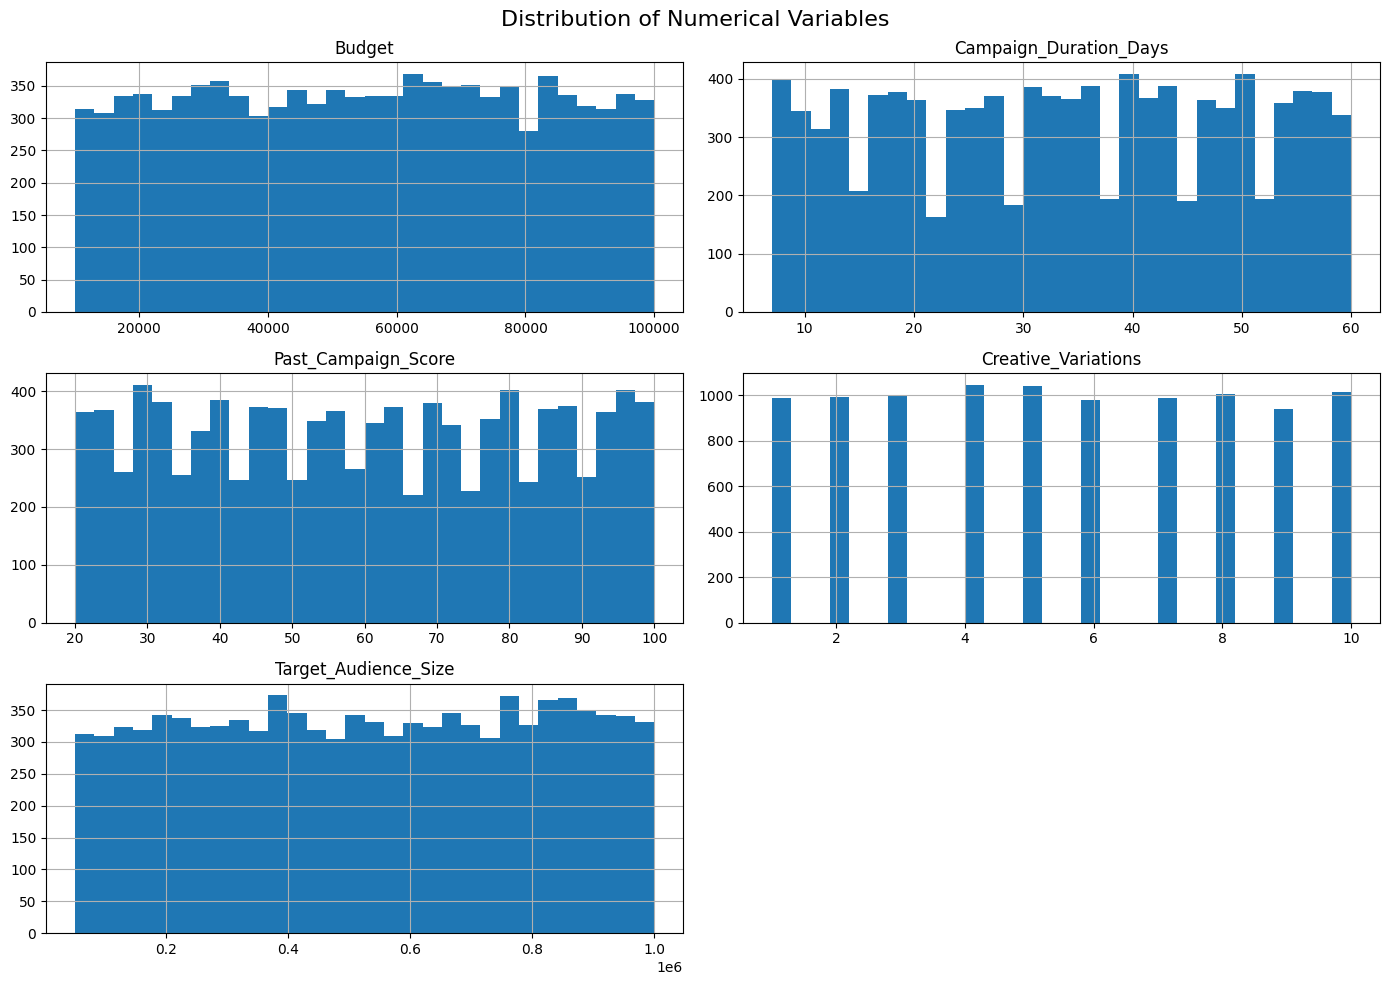

In [18]:
df[numerical_columns].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle(
    "Distribution of Numerical Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [19]:
# Identify numerical columns and categorical columns (the target is excluded)
numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = (
    df.select_dtypes(exclude="number")
    .columns.drop("Campaign_Success")
    .tolist()
)

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['Platform', 'Strategy', 'Campaign_Type', 'AI_Used', 'MMP_Used', 'Objective', 'Ad_Format', 'Audience_Type', 'Country', 'Industry', 'Agency', 'Campaign_Success']

Numerical Columns:
['Budget', 'Campaign_Duration_Days', 'Past_Campaign_Score', 'Creative_Variations', 'Target_Audience_Size']


In [ ]:
for column in categorical_columns:
    print(f"\n{'='*50}")
    print(column)
    print("="*50)
    print(df[column].value_counts())

In [21]:
# Target Variable Distribution
target_counts = df["Campaign_Success"].value_counts()

print(target_counts)

Campaign_Success
Yes    7000
No     3000
Name: count, dtype: int64


In [22]:
target_percentage = (
    df["Campaign_Success"]
    .value_counts(normalize=True) * 100
)

print(target_percentage)

Campaign_Success
Yes    70.0
No     30.0
Name: proportion, dtype: float64


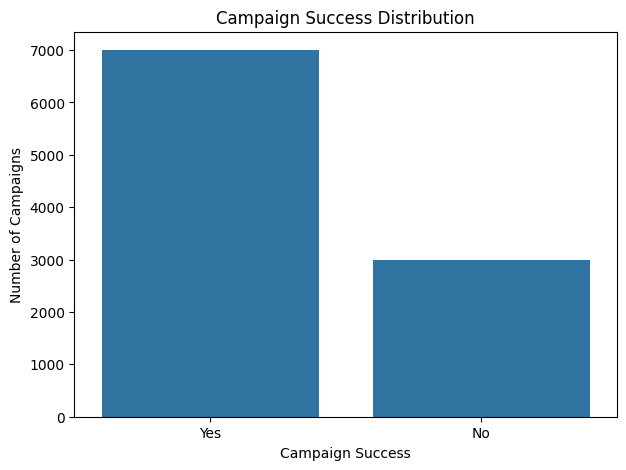

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Campaign_Success"
)

plt.title("Campaign Success Distribution")
plt.xlabel("Campaign Success")
plt.ylabel("Number of Campaigns")

plt.show()

In [ ]:
# One box plot per variable, because the variables are on very different scales
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(y=df[column], ax=ax)
    ax.set_title(column)

for ax in axes[len(numerical_columns):]:
    ax.set_visible(False)

fig.suptitle("Outlier Detection in Numerical Variables", fontsize=16)
plt.tight_layout()
plt.show()

In [26]:
#Correlation Analysis
# Calculate correlation matrix
correlation_matrix = df[numerical_columns].corr()

correlation_matrix

,Budget,Campaign_Duration_Days,Past_Campaign_Score,Creative_Variations,Target_Audience_Size
Budget,1.000000,0.013038,-0.002607,0.007471,-0.011575
Campaign_Duration_Days,0.013038,1.000000,-0.001457,-0.007603,0.005129
Past_Campaign_Score,-0.002607,-0.001457,1.000000,-0.023407,0.010439
Creative_Variations,0.007471,-0.007603,-0.023407,1.000000,0.011267
Target_Audience_Size,-0.011575,0.005129,0.010439,0.011267,1.000000


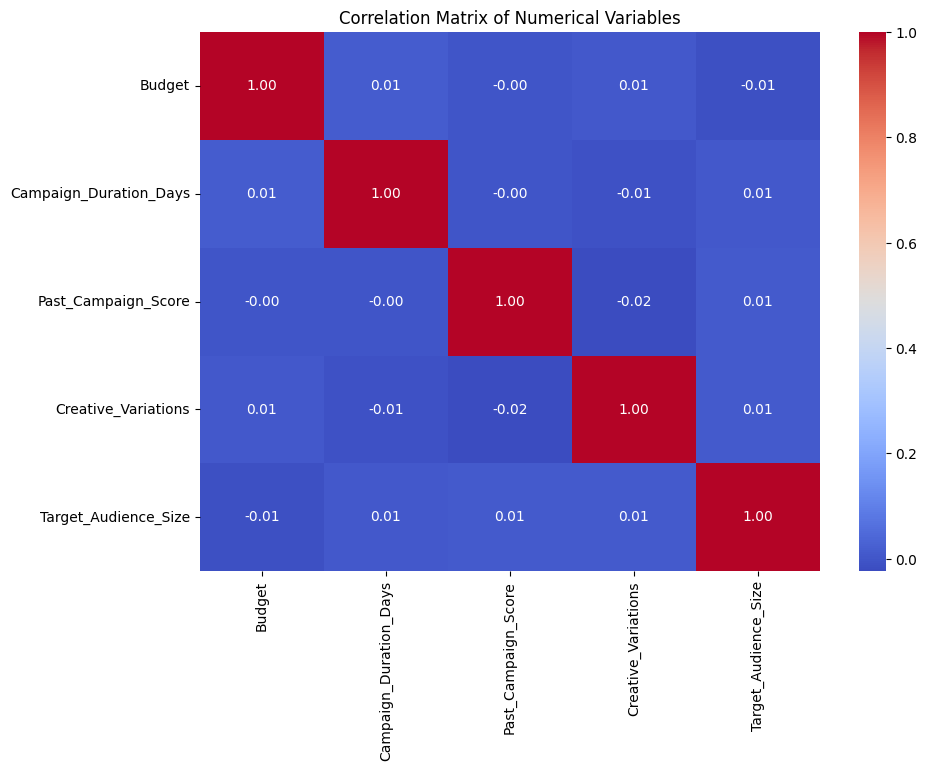

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix of Numerical Variables")

plt.show()

### Relationship Between Features and Campaign Success

The earlier plots describe each variable on its own. The charts below show how the success rate changes across categories and how the numerical variables differ between successful and unsuccessful campaigns.

This is the most direct way to see which campaign characteristics are associated with success, and it provides a check on the model results later in the notebook.

In [ ]:
# Success rate by category (red dashed line = overall success rate)
success_flag = (df["Campaign_Success"] == "Yes").astype(int)
overall_rate = success_flag.mean()

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.ravel()

for ax, column in zip(axes, categorical_columns):
    rate = success_flag.groupby(df[column]).mean().sort_values()
    rate.plot(kind="barh", ax=ax)
    ax.axvline(overall_rate, color="red", linestyle="--", linewidth=1)
    ax.set_title(column)
    ax.set_xlabel("Success rate")
    ax.set_ylabel("")
    ax.set_xlim(0, 1)

for ax in axes[len(categorical_columns):]:
    ax.set_visible(False)

fig.suptitle("Campaign Success Rate by Category", fontsize=16)
plt.tight_layout()
plt.show()

In [ ]:
# Numerical variables compared across successful and unsuccessful campaigns
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(
        data=df, x="Campaign_Success", y=column,
        order=["No", "Yes"], ax=ax
    )
    ax.set_title(f"{column} by Campaign_Success")

for ax in axes[len(numerical_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Feature and Target Definition

The dataset is divided into two components:

- **Features (X):** Variables used by the machine learning model to make predictions.
- **Target (y):** The outcome that the model is trained to predict.

The target variable for this project is `Campaign_Success`.

The dataset has no identifier column, so every remaining column is used as an input feature.

In [30]:
# Define features and target

X = df.drop(
    columns=["Campaign_Success"]
)

y = df["Campaign_Success"]

print("Features (X):", X.shape)
print("Target (y):", y.shape)

Features (X): (10000, 16)
Target (y): (10000,)


##  Train-Test Split

The dataset is divided into training and testing sets.

- **80%** of the observations are used to train the models.
- **20%** are reserved for evaluating model performance on unseen data.

Stratified sampling is used to maintain the same proportion of successful and unsuccessful campaigns in both datasets.

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8000, 16)
X_test: (2000, 16)
y_train: (8000,)
y_test: (2000,)


In [43]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 16)
Testing features: (2000, 16)

Training target distribution:
Campaign_Success
Yes    5600
No     2400
Name: count, dtype: int64

Testing target distribution:
Campaign_Success
Yes    1400
No      600
Name: count, dtype: int64


##  Feature Type Identification

The input features are separated into numerical and categorical variables.

This is required because the two types of variables require different preprocessing techniques before they can be used by machine learning algorithms.

In [33]:
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()
numerical_features = X_train.select_dtypes(include="number").columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Platform', 'Strategy', 'Campaign_Type', 'AI_Used', 'MMP_Used', 'Objective', 'Ad_Format', 'Audience_Type', 'Country', 'Industry', 'Agency']

Numerical Features:
['Budget', 'Campaign_Duration_Days', 'Past_Campaign_Score', 'Creative_Variations', 'Target_Audience_Size']


##  Data Preprocessing

Machine learning algorithms require numerical input.

The following preprocessing techniques are applied:

- Numerical features are standardized using `StandardScaler`.
- Categorical features are converted into numerical representations using `OneHotEncoder`.

A `ColumnTransformer` is used so that each preprocessing technique is applied only to the appropriate variables.

For categorical variables with only two levels (such as `AI_Used` and `MMP_Used`), one of the two encoded columns is dropped (`drop="if_binary"`). Keeping both would duplicate the same information and make Logistic Regression coefficients hard to interpret.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
            categorical_features
        )
    ]
)

## Baseline Model

About 70% of the campaigns are successful, so a model that always predicts "Yes" already reaches roughly 70% accuracy. This majority-class baseline is the minimum standard that every real model must clearly beat.

In [ ]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

baseline_model.fit(X_train, y_train)
y_pred_base = baseline_model.predict(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, y_pred_base))
print("Baseline F1 Score:", f1_score(y_test, y_pred_base, pos_label="Yes"))

# Model 1 — Logistic Regression

Logistic Regression is used as the baseline classification model.

It provides a simple and interpretable benchmark against which the other machine learning models can be compared.

In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ]
)

In [ ]:
logistic_model.fit(X_train, y_train)

In [ ]:
y_pred_lr = logistic_model.predict(X_test)

## Logistic Regression Evaluation

The Logistic Regression model is evaluated using multiple classification metrics.

The evaluation includes:

- Accuracy
- Precision
- Recall
- F1 Score
- Confusion Matrix

Using multiple metrics provides a more complete understanding of model performance than accuracy alone.

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr, pos_label="Yes"))
print("Recall   :", recall_score(y_test, y_pred_lr, pos_label="Yes"))
print("F1 Score :", f1_score(y_test, y_pred_lr, pos_label="Yes"))

## Model 2 — Decision Tree Classifier

A Decision Tree Classifier is trained to identify nonlinear relationships between campaign characteristics and campaign success.

Unlike Logistic Regression, a Decision Tree can capture interactions and nonlinear decision boundaries between features.

In [ ]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=6,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [ ]:
decision_tree_model.fit(X_train, y_train)

In [ ]:
y_pred_dt = decision_tree_model.predict(X_test)

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt, pos_label="Yes"))
print("Recall   :", recall_score(y_test, y_pred_dt, pos_label="Yes"))
print("F1 Score :", f1_score(y_test, y_pred_dt, pos_label="Yes"))

In [ ]:
print(classification_report(y_test, y_pred_dt))

##  Model 3 — Random Forest Classifier

A Random Forest Classifier is trained using multiple decision trees.

The ensemble approach can capture nonlinear relationships and interactions between campaign characteristics while reducing the limitations of a single decision tree.

The Random Forest model will be compared with Logistic Regression and Decision Tree using the same evaluation metrics.

In [ ]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=10,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

In [ ]:
random_forest_model.fit(X_train, y_train)

In [ ]:
y_pred_rf = random_forest_model.predict(X_test)

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf, pos_label="Yes"))
print("Recall   :", recall_score(y_test, y_pred_rf, pos_label="Yes"))
print("F1 Score :", f1_score(y_test, y_pred_rf, pos_label="Yes"))

In [ ]:
print(classification_report(y_test, y_pred_rf))

##  Model 4 — Gradient Boosting Classifier

Gradient Boosting is an ensemble classification algorithm that builds multiple decision trees sequentially.

Each new tree attempts to improve the errors made by the previous trees.

The model will be evaluated and compared with the previous classification models to determine which approach provides the best predictive performance for campaign success.

In [ ]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=RANDOM_STATE
            )
        )
    ]
)

In [ ]:
gradient_boosting_model.fit(X_train, y_train)

In [ ]:
y_pred_gb = gradient_boosting_model.predict(X_test)

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb, pos_label="Yes"))
print("Recall   :", recall_score(y_test, y_pred_gb, pos_label="Yes"))
print("F1 Score :", f1_score(y_test, y_pred_gb, pos_label="Yes"))

In [ ]:
print(classification_report(y_test, y_pred_gb))

## Initial Model Performance Comparison

The four models and the baseline are first compared on the test set using accuracy, precision, recall, and F1 score.

This is an initial look only. The **final model is chosen later using cross-validation on the training data**, so that the test set is not used to pick the winner.

In [ ]:
predictions = {
    "Baseline (majority class)": y_pred_base,
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
}


def evaluate(y_true, y_pred):
    """Return the four classification metrics, with 'Yes' as the positive class."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label="Yes"),
        "Recall": recall_score(y_true, y_pred, pos_label="Yes"),
        "F1 Score": f1_score(y_true, y_pred, pos_label="Yes"),
    }


results_df = pd.DataFrame(
    {name: evaluate(y_test, pred) for name, pred in predictions.items()}
).T

results_df

## Model Performance Visualization

The performance of the four classification models is visualized to make the differences between the models easier to interpret.

In [ ]:
results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Classification Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.legend(title="Metric")

plt.show()

##  Confusion Matrix Analysis

Confusion matrices are used to examine the classification errors made by each model.

The matrices show:

- True Negatives
- False Positives
- False Negatives
- True Positives

In [ ]:
model_predictions = {
    name: pred for name, pred in predictions.items()
    if not name.startswith("Baseline")
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, pred) in zip(axes.ravel(), model_predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=["No", "Yes"])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=ax
    )
    ax.set_title(f"Confusion Matrix - {name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

##  ROC-AUC Analysis

ROC-AUC is used to evaluate how effectively each model distinguishes between successful and unsuccessful campaigns.

A higher ROC-AUC indicates better class discrimination.

In [ ]:
all_models = {
    "Baseline (majority class)": baseline_model,
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
}

# predict_proba columns follow classes_ = ["No", "Yes"], so column 1 is P("Yes")
assert list(logistic_model.classes_) == ["No", "Yes"]

roc_results = {
    name: roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    for name, model in all_models.items()
}

roc_df = pd.DataFrame(roc_results.items(), columns=["Model", "ROC-AUC"])
roc_df

In [ ]:
plt.figure(figsize=(8, 6))

for name, model in all_models.items():
    if name.startswith("Baseline"):
        continue
    fpr, tpr, _ = roc_curve(
        y_test, model.predict_proba(X_test)[:, 1], pos_label="Yes"
    )
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_results[name]:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend(loc="lower right")
plt.show()

## Initial Comparison Summary

The table below combines all metrics, including ROC-AUC, for the baseline and the four models using their default settings.

Because these scores come from the test set, they are used for reference only. The next sections use cross-validation and hyperparameter tuning on the **training data** to choose the final model.

In [ ]:
results_final = results_df.copy()
results_final["ROC-AUC"] = pd.Series(roc_results)
results_final

## Cross-Validation

A single train-test split can be lucky or unlucky. **5-fold stratified cross-validation** on the training data gives a more stable estimate and shows how much each model's score varies from fold to fold.

The test set is not touched in this step.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "Accuracy": "accuracy",
    "F1": make_scorer(f1_score, pos_label="Yes"),
    "ROC-AUC": "roc_auc",
}

base_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
}

cv_rows = {}
for name, model in base_models.items():
    scores = cross_validate(clone(model), X_train, y_train, cv=cv, scoring=scoring)
    cv_rows[name] = {
        "CV Accuracy": scores["test_Accuracy"].mean(),
        "CV F1": scores["test_F1"].mean(),
        "CV ROC-AUC": scores["test_ROC-AUC"].mean(),
        "CV ROC-AUC Std": scores["test_ROC-AUC"].std(),
    }

cv_results_df = pd.DataFrame(cv_rows).T
cv_results_df

## Hyperparameter Tuning

A small grid search is run for each algorithm, scored by cross-validated ROC-AUC on the training data. This gives each model a fair chance, instead of comparing a tuned model against models with hand-picked settings.

In [ ]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10],
    },
    "Decision Tree": {
        "classifier__max_depth": [3, 5, 6, 8],
        "classifier__min_samples_leaf": [1, 20, 50],
    },
    "Random Forest": {
        "classifier__max_depth": [6, 10, None],
        "classifier__min_samples_leaf": [1, 5],
    },
    "Gradient Boosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3],
    },
}

tuned_models = {}
tuning_rows = {}

for name, model in base_models.items():
    search = GridSearchCV(
        clone(model), param_grids[name],
        scoring="roc_auc", cv=cv, n_jobs=-1
    )
    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_
    tuning_rows[name] = {
        "Best CV ROC-AUC": search.best_score_,
        "CV ROC-AUC Std": search.cv_results_["std_test_score"][search.best_index_],
        "Best Parameters": {
            k.replace("classifier__", ""): v
            for k, v in search.best_params_.items()
        },
    }

tuning_df = pd.DataFrame(tuning_rows).T
tuning_df["Best CV ROC-AUC"] = tuning_df["Best CV ROC-AUC"].astype(float)
tuning_df["CV ROC-AUC Std"] = tuning_df["CV ROC-AUC Std"].astype(float)
tuning_df

## Final Model Selection

The final model is the one with the highest cross-validated ROC-AUC after tuning. Its performance is then measured **once** on the test set, which was not used for any selection decision.

If the top two models differ by less than the cross-validation standard deviation, the difference is not meaningful, and the simpler, more interpretable model is the better practical choice.

In [ ]:
ranking = tuning_df["Best CV ROC-AUC"].sort_values(ascending=False)

final_name = ranking.index[0]
final_model = tuned_models[final_name]

print("Selected final model:", final_name)
print("Best parameters     :", tuning_df.loc[final_name, "Best Parameters"])
print(f"CV ROC-AUC          : {ranking.iloc[0]:.4f} (+/- {tuning_df.loc[final_name, 'CV ROC-AUC Std']:.4f})")
print(f"Gap to runner-up ({ranking.index[1]}): {ranking.iloc[0] - ranking.iloc[1]:.4f}")

In [ ]:
# One-time evaluation of the final model on the untouched test set
y_pred_final = final_model.predict(X_test)
y_prob_final = final_model.predict_proba(X_test)[:, 1]

final_metrics = evaluate(y_test, y_pred_final)
final_metrics["ROC-AUC"] = roc_auc_score(y_test, y_prob_final)

print(f"Final model: {final_name}\n")
for metric, value in final_metrics.items():
    print(f"{metric:<10}: {value:.4f}")

print("\n", classification_report(y_test, y_pred_final))

cm_final = confusion_matrix(y_test, y_pred_final, labels=["No", "Yes"])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_final, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"]
)
plt.title(f"Confusion Matrix - {final_name} (Final Model)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Save the trained pipeline (preprocessing + model) for reuse
joblib.dump(final_model, "campaign_success_model.joblib")

## Feature Importance Analysis

Feature importance shows which campaign characteristics matter most for the final model's predictions.

**Permutation importance** is used. Each original input column is shuffled in turn on the test set, and the drop in ROC-AUC is measured. A larger drop means the model relies more on that column.

This method works for any model, and it gives one score per original variable. That avoids the problems of summing one-hot coefficients, where variables with more categories look more important and numerical and categorical coefficients are not comparable.

In [ ]:
perm = permutation_importance(
    final_model, X_test, y_test,
    scoring="roc_auc", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1
)

importance_df = (
    pd.DataFrame({
        "Feature": X_test.columns,
        "Importance (drop in ROC-AUC)": perm.importances_mean,
        "Std": perm.importances_std,
    })
    .sort_values("Importance (drop in ROC-AUC)", ascending=False)
    .reset_index(drop=True)
)

importance_df

In [ ]:
plot_df = importance_df.sort_values("Importance (drop in ROC-AUC)")

plt.figure(figsize=(10, 7))
plt.barh(
    plot_df["Feature"],
    plot_df["Importance (drop in ROC-AUC)"],
    xerr=plot_df["Std"]
)
plt.xlabel("Drop in ROC-AUC when the feature is shuffled")
plt.ylabel("Feature")
plt.title(f"Permutation Feature Importance - {final_name}")
plt.tight_layout()
plt.show()

In [ ]:
# Success rate for the most important features (to check what the model relies on)
top_features = importance_df["Feature"].head(6).tolist()

for feature in top_features:
    if feature in categorical_features:
        grouped = success_flag.groupby(df[feature])
    else:
        grouped = success_flag.groupby(pd.qcut(df[feature], 4, duplicates="drop"))

    table = grouped.agg(["mean", "count"]).rename(
        columns={"mean": "Success rate", "count": "Campaigns"}
    )
    print(f"\n{feature}")
    print(table.round(3).to_string())

## Business Insights

*Check each statement below against the importance chart and the success-rate tables above.*

1. **Past performance is the strongest signal.** Campaigns with a higher `Past_Campaign_Score` are much more likely to succeed. Teams should use track record when deciding where to invest.
2. **Strategy and campaign type matter.** Performance Marketing and Conversion campaigns are associated with higher success, while Content Marketing and Social Media Marketing are associated with lower success.
3. **Campaign set-up matters.** Campaigns that use AI tools and an MMP (mobile measurement partner), and campaigns with a Sales objective, are associated with higher success.
4. **Platform, agency, industry, country, and duration add little.** These variables have a small influence on the prediction, so choosing among them should not be the main focus when planning a campaign.

### Recommendations

- Screen new campaign plans with the model before committing budget, and review plans with low predicted success probability.
- Prioritise strategy, campaign type, objective, and tracking set-up, because these are the factors most associated with success.
- Treat these findings as **associations, not causes**. The model shows which characteristics go with success in this dataset, not that changing them will cause success.

# Test the Model on a New Campaign

## Testing the Model on New Marketing Campaigns

The final selected model (`final_model`) is now used to predict the outcome of new marketing campaigns.

Three hypothetical campaigns are created with the same input variables used in training: a strong one, an average one, and a weak one. Testing only a strong campaign would not show whether the model can also predict an unsuccessful outcome.

The actual outcome is not provided. The model uses only the campaign characteristics.

## Campaign Success Prediction

Each campaign is passed through the final pipeline, which applies the same preprocessing as in training and returns a predicted outcome with its probability.

In [ ]:
new_campaign = pd.DataFrame({
    "Platform": ["Google Ads"],
    "Strategy": ["Performance Marketing"],
    "Campaign_Type": ["Conversion"],
    "AI_Used": ["Yes"],
    "MMP_Used": ["Yes"],
    "Objective": ["Sales"],
    "Budget": [75000],
    "Campaign_Duration_Days": [30],
    "Past_Campaign_Score": [82],
    "Audience_Type": ["Existing"],
    "Creative_Variations": [5],
    "Target_Audience_Size": [500000],
    "Country": ["India"],
    "Industry": ["E-commerce"],
    "Agency": ["Agency A"],
    "Ad_Format": ["Video"]
})

In [ ]:
print(new_campaign.columns.tolist())

# Every category in the new campaign must have been seen during training
for col in categorical_features:
    unseen = set(new_campaign[col]) - set(X_train[col])
    assert not unseen, f"Unseen category in {col}: {unseen}"

print("All categories in the new campaign were seen during training.")

In [ ]:
def make_campaign(**changes):
    """Copy the strong campaign and change only the listed fields."""
    row = new_campaign.iloc[0].to_dict()
    row.update(changes)
    return pd.DataFrame([row])


scenarios = {
    "Strong campaign": new_campaign,
    "Average campaign": make_campaign(
        Strategy="Search Marketing",
        Campaign_Type="Traffic",
        Objective="Engagement",
        AI_Used="No",
        Past_Campaign_Score=55,
    ),
    "Weak campaign": make_campaign(
        Platform="LinkedIn",
        Strategy="Content Marketing",
        Campaign_Type="Brand Awareness",
        Objective="Awareness",
        AI_Used="No",
        MMP_Used="No",
        Budget=20000,
        Campaign_Duration_Days=10,
        Past_Campaign_Score=25,
        Creative_Variations=2,
        Ad_Format="Text",
    ),
}

assert list(final_model.classes_) == ["No", "Yes"]

rows = []
for name, campaign in scenarios.items():
    prob_yes = final_model.predict_proba(campaign)[0, 1]
    rows.append({
        "Scenario": name,
        "Predicted Outcome": final_model.predict(campaign)[0],
        "Probability of Success (%)": round(prob_yes * 100, 2),
    })

pd.DataFrame(rows)

In [ ]:
# Final results summary
print(f"Final model                      : {final_name}")
print(f"Majority-class baseline accuracy : {results_df.loc['Baseline (majority class)', 'Accuracy']:.2%}")
print(f"Cross-validated ROC-AUC (train)  : {tuning_df.loc[final_name, 'Best CV ROC-AUC']:.4f}")

for metric, value in final_metrics.items():
    print(f"Test {metric:<10}               : {value:.4f}")

print("Top 5 drivers                    :", ", ".join(importance_df["Feature"].head(5)))

# Machine Learning Conclusion

This project built a supervised classification system to predict whether a marketing campaign will be successful (`Campaign_Success` = Yes or No) using 10,000 campaign records and 16 input features.

**Approach**

1. The data was checked for missing values and duplicates (none found), and explored for distributions, outliers, correlations, and each feature's relationship with the target.
2. The data was split 80/20 with stratification. All preprocessing (scaling and one-hot encoding) was done inside a pipeline, which avoids data leakage.
3. A majority-class baseline and four algorithms were evaluated: Logistic Regression, Decision Tree, Random Forest, and Gradient Boosting.
4. The models were compared with 5-fold cross-validation and a small grid search on the training data. The final model was chosen by cross-validated ROC-AUC, and then evaluated once on the test set.
5. Feature importance was measured with permutation importance on the final model, and the model was tested on strong, average, and weak hypothetical campaigns.

**Results**

The final model, its cross-validated score, its test-set metrics, and the top drivers are printed in the summary cell above. The final model clearly outperforms the majority-class baseline, and the strongest predictors are campaign track record (`Past_Campaign_Score`) together with strategy, campaign type, objective, and tooling choices.

**Limitations**

- The dataset appears to be synthetic. A simple linear model performing so well suggests the outcome follows a fairly regular pattern, which real campaign data rarely does. Predictions here represent statistical patterns in this dataset and are not a guarantee of real-world campaign performance.
- Feature importance shows association, not causation.
- The model should be re-validated on real campaign data before being used for budget decisions.

**Final Outcome**

The final trained pipeline is saved as `campaign_success_model.joblib` and can be used as a decision-support tool for evaluating a new campaign before launch.

**Possible next steps:** business visualisation in Power BI or Tableau, and integration with the RAG component.